In [2]:
# 96k rows wala data 
# 1. IMPORTS
# ==============================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

C:\Users\ASUS\AppData\Local\Temp\ipykernel_22740\3829960414.py:4: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [3]:
# 2. LOAD DATA
# ==============================
df = pd.read_csv("../delhi-aqi-prediction-using-ml/data/delhi_final_clean.csv")

df["datetime"] = pd.to_datetime(df["datetime"])
df = df.sort_values("datetime")

In [4]:
# 3. TIME-BASED SPLIT (FIXED)
# ==============================
train_df = df[df["datetime"] < "2022-01-01"]
test_df = df[df["datetime"] >= "2022-01-01"]

features = ["pm25","pm10","no2","so2","co","o3"]

X_train = train_df[features]
y_train = train_df["aqi"]

X_test = test_df[features]
y_test = test_df["aqi"]

In [5]:
# 4. LINEAR REGRESSION
# ==============================
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

In [6]:
# 5. RANDOM FOREST
# ==============================
rf = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)


In [7]:
# 6. SVR
# ==============================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svr = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1)
svr.fit(X_train_scaled, y_train)
y_pred_svr = svr.predict(X_test_scaled)

In [8]:
# 7. ARIMA
# ==============================
df_ts = df.copy()
df_ts.set_index("datetime", inplace=True)

ts = df_ts["aqi"].resample("H").mean().ffill()

train_ts = ts[:'2021-12-31']
test_ts = ts['2022-01-01':]

arima_model = ARIMA(train_ts, order=(2,1,2))
arima_fit = arima_model.fit()
arima_pred = arima_fit.forecast(len(test_ts))


C:\Users\ASUS\AppData\Local\Temp\ipykernel_22740\1106644833.py:6: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  ts = df_ts["aqi"].resample("H").mean().ffill()


In [9]:
# 8. SARIMA
# ==============================
sarima_model = SARIMAX(train_ts, order=(2,1,2), seasonal_order=(1,1,1,24))
sarima_fit = sarima_model.fit()
sarima_pred = sarima_fit.forecast(len(test_ts))


MemoryError: Unable to allocate 1.24 GiB for an array with shape (52, 52, 61367) and data type float64

In [10]:
# 9. EVALUATION
# ==============================
def evaluate(y_true, y_pred):
    return [
        r2_score(y_true, y_pred),
        mean_absolute_error(y_true, y_pred),
        np.sqrt(mean_squared_error(y_true, y_pred))
    ]

results = pd.DataFrame({
    "Model": ["LR", "Random Forest", "SVR", "ARIMA"],
    "R2": [
        evaluate(y_test, y_pred_lr)[0],
        evaluate(y_test, y_pred_rf)[0],
        evaluate(y_test, y_pred_svr)[0],
        evaluate(test_ts, arima_pred)[0],
        # evaluate(test_ts, sarima_pred)[0]
    ],
    "MAE": [
        evaluate(y_test, y_pred_lr)[1],
        evaluate(y_test, y_pred_rf)[1],
        evaluate(y_test, y_pred_svr)[1],
        evaluate(test_ts, arima_pred)[1],
        # evaluate(test_ts, sarima_pred)[1]
    ],
    "RMSE": [
        evaluate(y_test, y_pred_lr)[2],
        evaluate(y_test, y_pred_rf)[2],
        evaluate(y_test, y_pred_svr)[2],
        evaluate(test_ts, arima_pred)[2],
        # evaluate(test_ts, sarima_pred)[2]
    ]
})

print("\nModel Comparison:\n")
print(results.round(3))



Model Comparison:

           Model     R2      MAE     RMSE
0             LR  0.665   85.016   97.283
1  Random Forest  0.999    2.890    5.020
2            SVR  0.998    5.491    8.309
3          ARIMA -1.919  233.220  287.277


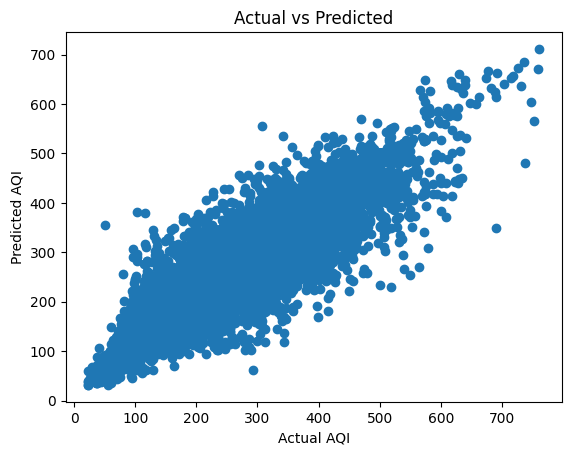

In [ ]:
# 10. PLOTS
# ==============================
plt.figure(figsize=(10,5))
plt.plot(y_test.values, label="Actual")
plt.plot(y_pred_rf, label="RF")
plt.legend()
plt.title("Random Forest Prediction")
plt.show()

plt.figure(figsize=(10,5))
plt.plot(test_ts.values, label="Actual")
plt.plot(sarima_pred.values, label="SARIMA")
plt.legend()
plt.title("SARIMA Prediction")
plt.show()

In [ ]:
# 11. SAVE MODELS (FIXED)
# ==============================
joblib.dump(rf, "models/rf_model.pkl")

joblib.dump(svr, "models/svr_model.pkl")
joblib.dump(scaler, "models/scaler.pkl")

arima_fit.save("models/arima_model.pkl")
sarima_fit.save("models/sarima_model.pkl")


SVR R2: 0.9968964614574111
SVR MAE: 6.382899753948502
